In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

La duración de un proyecto puede escribirse como una fórmula cerrada: si $R$ es la matriz de rutas (una fila por cada ruta del nodo inicial al final, una columna por actividad, con un 1 donde la actividad pertenece a la ruta) y $t$ el vector de duraciones, entonces

$$\tau = \lVert R\,t \rVert_\infty = \max_r \sum_i R_{ri}\,t_i .$$

Considere el proyecto cuyo cuadro de prelaciones y duraciones (días) se adjunta.

In [4]:
pregunta_1 = "1. Dibuje el grafo PERT, enumere sus rutas y construya la matriz de rutas R. ¿Qué dimensiones tiene?  "
pregunta_2 = "2. Calcule el vector R·t y su norma infinito. Compruebe que coincide con el tiempo más temprano del último nodo obtenido por el método de Zaderenko.  "
pregunta_3 = "3. ¿Por qué la norma infinito y no otra? ¿Qué daría ‖R·t‖₁? ¿Y qué significaría el mínimo de R·t?  "
pregunta_4 = "4. Escriba τ en función de t_G (la duración de G) dejando fijas las demás, y dibuje esa función. ¿Es lineal? ¿Dónde cambia de pendiente?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Dibuje el grafo PERT, enumere sus rutas y construya la matriz de rutas R. ¿Qué dimensiones tiene?  

2. Calcule el vector R·t y su norma infinito. Compruebe que coincide con el tiempo más temprano del último nodo obtenido por el método de Zaderenko.  

3. ¿Por qué la norma infinito y no otra? ¿Qué daría ‖R·t‖₁? ¿Y qué significaría el mínimo de R·t?  

4. Escriba τ en función de t_G (la duración de G) dejando fijas las demás, y dibuje esa función. ¿Es lineal? ¿Dónde cambia de pendiente?  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 4       ),
    ('B'     , '---'      , 5       ),
    ('C'     , 'A,B'      , 2       ),
    ('D'     , 'C'        , 3       ),
    ('E'     , 'D'        , 5       ),
    ('F'     , 'D'        , 8       ),
    ('G'     , 'F'        , 8       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
datos_enunciado

,predecessor,duration
activity,,
A,---,4
B,---,5
C,"A,B",2
D,C,3
E,D,5
F,D,8
G,F,8


El proyecto corresponde a la instalación de una planta fotovoltaica sobre cubierta; las actividades son las siguientes (las duraciones del cuadro están en días).

In [6]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Estudio de sombras y producción',
    'B': 'Cálculo estructural de la cubierta',
    'C': 'Tramitación de permisos',
    'D': 'Acopio de módulos e inversores',
    'E': 'Montaje de la estructura soporte',
    'F': 'Colocación de módulos',
    'G': 'Cableado de corriente continua',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Estudio de sombras y producción
B,Cálculo estructural de la cubierta
C,Tramitación de permisos
D,Acopio de módulos e inversores
E,Montaje de la estructura soporte
F,Colocación de módulos
G,Cableado de corriente continua


# Resolución

In [7]:
def bmatrix(a, dec=0):
    """Matriz LaTeX (bmatrix) a partir de un DataFrame o array."""
    a = np.asarray(getattr(a, 'values', a), dtype=float)
    if a.ndim == 1:
        a = a.reshape(-1, 1)
    filas = [' & '.join(f'{x:.{dec}f}' for x in fila) + r'\\' for fila in a]
    return r'\begin{bmatrix}' + '\n' + '\n'.join(filas) + '\n' + r'\end{bmatrix}'

In [8]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
R = proyecto.path_matrix(dummies=False)
t = datos_proyecto['duration'][R.columns]

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. Dibuje el grafo PERT, enumere sus rutas y construya la matriz de rutas R. ¿Qué dimensiones tiene?  

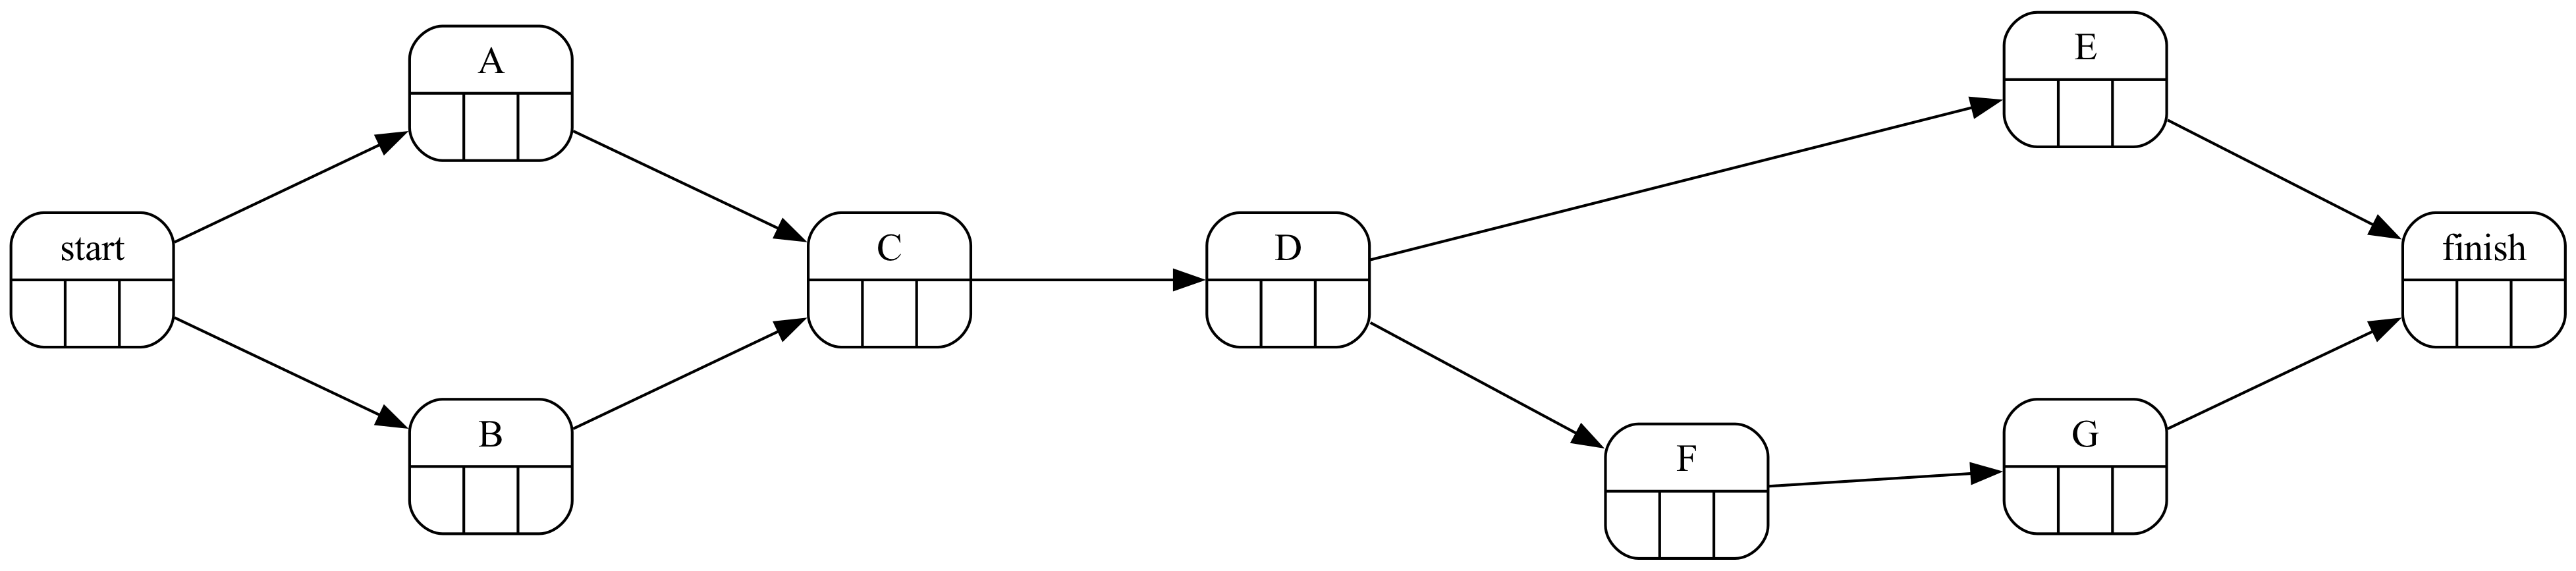

In [10]:
#| fig-cap: "Grafo Roy"
#| label: fig-pert
proyecto.display_roy_construccion(tabla=prelaciones)

In [11]:
#| tbl-cap: "Matriz de rutas R"
#| label: tbl-R
rutas = proyecto.paths(dummies=False)
display(pd.Series({r: ' - '.join(a) for r, a in rutas.items()}).to_frame('actividades'))
proyecto.display_rutas("roy")

,actividades
Route_1,A - C - D - E
Route_2,A - C - D - F - G
Route_3,B - C - D - E
Route_4,B - C - D - F - G


,A,B,C,D,E,F,G
Route_1,1,0,1,1,1,0,0
Route_2,1,0,1,1,0,1,1
Route_3,0,1,1,1,1,0,0
Route_4,0,1,1,1,0,1,1


In [12]:
Markdown(f'R tiene {R.shape[0]} filas (rutas) y {R.shape[1]} columnas (actividades).')

R tiene 4 filas (rutas) y 7 columnas (actividades).

## Apartado 2

In [13]:
display(Markdown(pregunta_2))

2. Calcule el vector R·t y su norma infinito. Compruebe que coincide con el tiempo más temprano del último nodo obtenido por el método de Zaderenko.  

In [14]:
Rt = R @ t
tau = float(Rt.max())
Math(bmatrix(R) + r' \times ' + bmatrix(t) + ' = ' + bmatrix(Rt) + r' \quad\Rightarrow\quad \tau = ' + f'{tau:.0f}')

<IPython.core.display.Math object>

Algoritmo de Zaderenko paso a paso, con el grafo PERT arriba y la matriz debajo. El primer paso muestra el resultado final; a partir del siguiente se construye desde el principio (avance con los botones):

In [15]:
#| tbl-cap: "Matriz de Zaderenko"
#| label: tbl-zaderenko
proyecto.display_zaderenko_tikz(datos_proyecto['duration'])

,1,2,3,4,5,6,7,early
1,,4.0,5.0,,,,,0.0
2,,,0.0,,,,,4.0
3,,,,2.0,,,,5.0
4,,,,,3.0,,,7.0
5,,,,,,8.0,5.0,10.0
6,,,,,,,8.0,18.0
7,,,,,,,,26.0
late,0.0,5.0,5.0,7.0,10.0,18.0,26.0,


In [16]:
Markdown(f'‖R·t‖∞ = {tau:.0f}; tiempo más temprano del último nodo = {proyecto.duration(datos_proyecto["duration"])}; '
         f'la librería (`proyecto.tau`) da {proyecto.tau(t.to_dict()):.0f}. Las tres coinciden: el cálculo de tiempos hacia delante es una forma de calcular el máximo sin enumerar las rutas.')

‖R·t‖∞ = 26; tiempo más temprano del último nodo = 26; la librería (`proyecto.tau`) da 26. Las tres coinciden: el cálculo de tiempos hacia delante es una forma de calcular el máximo sin enumerar las rutas.

## Apartado 3

In [17]:
display(Markdown(pregunta_3))

3. ¿Por qué la norma infinito y no otra? ¿Qué daría ‖R·t‖₁? ¿Y qué significaría el mínimo de R·t?  

In [18]:
Markdown(f'''‖R·t‖₁ = {float(Rt.abs().sum()):.0f} sumaría las duraciones de todas las rutas, contando varias veces cada actividad compartida: no tiene sentido como plazo. El mínimo de R·t, {float(Rt.min()):.0f}, es la ruta más corta: el tiempo que *como mínimo* ocupa cualquier cadena del proyecto, pero el proyecto no termina hasta que acaba la última ruta. El plazo es el máximo porque todas las rutas deben completarse; de ahí la norma infinito.''')

‖R·t‖₁ = 80 sumaría las duraciones de todas las rutas, contando varias veces cada actividad compartida: no tiene sentido como plazo. El mínimo de R·t, 14, es la ruta más corta: el tiempo que *como mínimo* ocupa cualquier cadena del proyecto, pero el proyecto no termina hasta que acaba la última ruta. El plazo es el máximo porque todas las rutas deben completarse; de ahí la norma infinito.

## Apartado 4

In [19]:
display(Markdown(pregunta_4))

4. Escriba τ en función de t_G (la duración de G) dejando fijas las demás, y dibuje esa función. ¿Es lineal? ¿Dónde cambia de pendiente?  

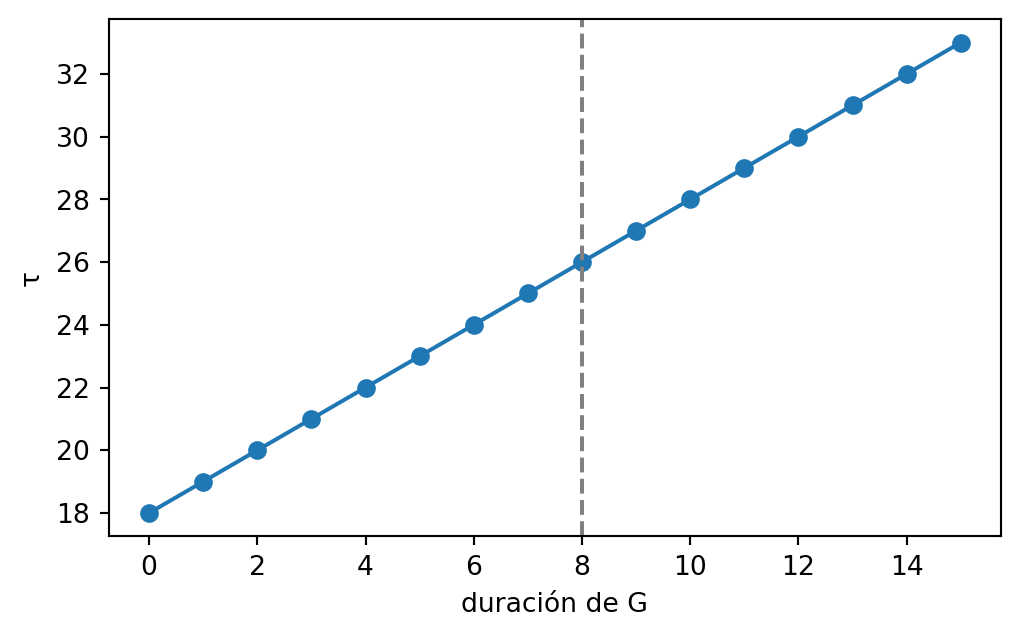

In [20]:
k = 'G'
valores = np.arange(0, int(t[k]) + 8)
taus = []
for v in valores:
    t2 = t.copy(); t2[k] = v
    taus.append(float((R @ t2).max()))
pendiente = np.diff(taus)
codo = int(valores[np.argmax(pendiente > 0)]) if (pendiente > 0).any() else None
from matplotlib import pyplot as plt
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(valores, taus, marker='o'); ax.axvline(int(t[k]), color='grey', linestyle='--')
ax.set_xlabel(f'duración de {k}'); ax.set_ylabel('τ'); plt.show()

In [21]:
Markdown(f'''τ es el máximo de varias funciones lineales de t_{k} (una por ruta): las rutas que no contienen a {k} son constantes y las que la contienen tienen pendiente 1. El resultado es lineal a trozos y convexo: pendiente 0 mientras otra ruta manda y pendiente 1 a partir de t_{k} = {codo} (cuando la ruta más larga que pasa por {k} alcanza a la crítica). La duración actual de {k} es {int(t[k])}: su sensibilidad es {int(pendiente[list(valores).index(int(t[k]))])}.''')

τ es el máximo de varias funciones lineales de t_G (una por ruta): las rutas que no contienen a G son constantes y las que la contienen tienen pendiente 1. El resultado es lineal a trozos y convexo: pendiente 0 mientras otra ruta manda y pendiente 1 a partir de t_G = 0 (cuando la ruta más larga que pasa por G alcanza a la crítica). La duración actual de G es 8: su sensibilidad es 1.